# CSCI218 Group Project: Optimizing Last-Mile Delivery Routes Using Genetic Algorithms
**Topic 9: Travelling Salesman Problem (TSP)**

### Overview
Delivery platforms like Talabat regularly assign multiple customer drop-offs to a single driver in one trip. Finding the shortest route between all stops is a classic Travelling Salesman Problem (TSP)—as the number of stops grows, checking every possible path becomes computationally impossible.

In this notebook, we use real delivery GPS coordinates from `talabat_enhanced_orders.csv` to build a **Genetic Algorithm (GA)** that finds near-optimal delivery routes. We compare its distance and execution time against two baselines:
* **Brute-Force Search** (exact optimal route for small stop counts)
* **Greedy Nearest-Neighbor** (fast heuristic baseline)




*Step 1: Setup and Data downloading*

In [1]:
import itertools
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Keep results reproducible across runs
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

raw_df = pd.read_csv("/talabat_enhanced_orders.csv")

# Filter for Cairo orders and grab 14 drop-offs + 1 driver starting point (15 stops total)
SELECTED_CITY = "Cairo"
NUM_DROPOFFS = 14

city_orders = raw_df[raw_df["City"] == SELECTED_CITY].reset_index(drop=True)
sample_orders = city_orders.iloc[:NUM_DROPOFFS]

# Node 0 is where the driver starts; Nodes 1-14 are customer locations
locations = [{
    "ID": 0,
    "Label": f"Driver Start (Order #{sample_orders.loc[0, 'Order_ID']})",
    "lat": sample_orders.loc[0, "Driver_Lat"],
    "lon": sample_orders.loc[0, "Driver_Lon"],
}]

for idx, row in sample_orders.iterrows():
  locations.append({
      "ID": idx + 1,
      "Label": f"Order #{row['Order_ID']} ({row['Item_Name']})",
      "lat": row["Customer_Lat"],
      "lon": row["Customer_Lon"],
  })

nodes_df = pd.DataFrame(locations)


def haversine(lat1, lon1, lat2, lon2):
  # Straight-line distance in km between two lat/lon points on Earth
  R = 6371.0
  dlat = np.radians(lat2 - lat1)
  dlon = np.radians(lon2 - lon1)
  a = (
      np.sin(dlat / 2) ** 2
      + np.cos(np.radians(lat1))
      * np.cos(np.radians(lat2))
      * np.sin(dlon / 2) ** 2
  )
  return 2 * R * np.arcsin(np.sqrt(a))


# Build an N x N matrix storing distances between every pair of stops
coords = nodes_df[["lat", "lon"]].values
n = len(coords)
dist_matrix = np.zeros((n, n))

for i in range(n):
  for j in range(n):
    if i != j:
      dist_matrix[i][j] = haversine(
          coords[i][0], coords[i][1], coords[j][0], coords[j][1]
      )


def route_distance(tour, matrix):
  # Total loop distance starting and returning to Node 0
  dist = sum(matrix[tour[i]][tour[i + 1]] for i in range(len(tour) - 1))
  return dist + matrix[tour[-1]][tour[0]]


print(f"Loaded {n} stops in {SELECTED_CITY}.")
nodes_df.head()

Loaded 15 stops in Cairo.


,ID,Label,lat,lon
0,0,Driver Start (Order #7),30.038769,31.231835
1,1,Order #7 (Sushi),30.043525,31.233372
2,2,Order #10 (Pizza),30.025107,31.229281
3,3,Order #15 (Burger),30.031402,31.225295
4,4,Order #22 (Pizza),30.041003,31.220671


*Step 2: Baseline Algorithms (Brute-Force & Greedy)*

In [2]:
def brute_force_tsp(matrix):
  # Checks every possible permutation; only practical for ~10 or fewer stops
  start = time.perf_counter()
  other_stops = list(range(1, len(matrix)))
  best_tour, min_dist = None, float("inf")

  for perm in itertools.permutations(other_stops):
    tour = [0] + list(perm)
    d = route_distance(tour, matrix)
    if d < min_dist:
      min_dist = d
      best_tour = tour

  return best_tour, min_dist, time.perf_counter() - start


def greedy_tsp(matrix, start_node=0):
  # Always picks the closest unvisited stop next
  start = time.perf_counter()
  unvisited = set(range(len(matrix))) - {start_node}
  tour = [start_node]
  curr = start_node

  while unvisited:
    nxt = min(unvisited, key=lambda city: matrix[curr][city])
    tour.append(nxt)
    unvisited.remove(nxt)
    curr = nxt

  return tour, route_distance(tour, matrix), time.perf_counter() - start

*Step 3: Genetic Algorithm*

In [3]:
def create_population(pop_size, num_stops):
  # Create random valid routes that all start at Node 0
  stops = list(range(1, num_stops))
  return [[0] + random.sample(stops, len(stops)) for _ in range(pop_size)]


def tournament_select(population, fitnesses, k=5):
  # Pick k random routes and return the fittest one
  candidates = random.sample(range(len(population)), k)
  winner = max(candidates, key=lambda idx: fitnesses[idx])
  return population[winner]


def ordered_crossover(parent1, parent2):
  # Copy a slice from parent1 and fill the rest in parent2's order to avoid duplicate stops
  p1, p2 = parent1[1:], parent2[1:]
  size = len(p1)
  a, b = sorted(random.sample(range(size), 2))

  child = [None] * size
  child[a : b + 1] = p1[a : b + 1]

  remaining = [stop for stop in p2 if stop not in child]
  idx = 0
  for i in range(size):
    if child[i] is None:
      child[i] = remaining[idx]
      idx += 1

  return [0] + child


def inversion_mutation(tour, mut_rate):
  # Reverse a random segment of the route to untangle crossing paths
  route = tour[:]
  if random.random() < mut_rate:
    a, b = sorted(random.sample(range(1, len(route)), 2))
    route[a : b + 1] = reversed(route[a : b + 1])
  return route


def run_genetic_algorithm(
    matrix,
    pop_size=120,
    generations=400,
    crossover_rate=0.85,
    mutation_rate=0.15,
    elitism=4,
):
  start = time.perf_counter()
  population = create_population(pop_size, len(matrix))

  history = []
  best_tour = None
  best_dist = float("inf")

  for _ in range(generations):
    distances = [route_distance(ind, matrix) for ind in population]
    fitnesses = [1.0 / d for d in distances]

    gen_best_idx = int(np.argmin(distances))
    if distances[gen_best_idx] < best_dist:
      best_dist = distances[gen_best_idx]
      best_tour = population[gen_best_idx][:]

    history.append(best_dist)

    # Carry the top routes straight into the next generation
    ranked = np.argsort(distances)
    next_gen = [population[i][:] for i in ranked[:elitism]]

    while len(next_gen) < pop_size:
      p1 = tournament_select(population, fitnesses)
      p2 = tournament_select(population, fitnesses)

      child = (
          ordered_crossover(p1, p2) if random.random() < crossover_rate else p1[:]
      )
      child = inversion_mutation(child, mutation_rate)
      next_gen.append(child)

    population = next_gen

  return best_tour, best_dist, history, time.perf_counter() - start

*Step 4: Experiments and Comparison*

In [4]:
# 1. Small 9-stop test to verify GA against exact Brute-Force
sub_matrix = dist_matrix[:9, :9]
bf_tour, bf_dist, bf_time = brute_force_tsp(sub_matrix)
gr_sub_tour, gr_sub_dist, gr_sub_time = greedy_tsp(sub_matrix)
ga_sub_tour, ga_sub_dist, _, ga_sub_time = run_genetic_algorithm(
    sub_matrix, pop_size=80, generations=200
)

print(f"--- 9-Stop Subset ({SELECTED_CITY}) ---")
print(f"Brute-Force : {bf_dist:.2f} km ({bf_time:.4f}s)")
print(f"Greedy      : {gr_sub_dist:.2f} km ({gr_sub_time:.6f}s)")
print(f"GA          : {ga_sub_dist:.2f} km ({ga_sub_time:.4f}s)\n")

# 2. Full 15-stop benchmark averaged over 10 runs
greedy_tour, greedy_dist, greedy_time = greedy_tsp(dist_matrix)

ga_dists, ga_times, ga_histories = [], [], []
best_ga_tour, best_ga_dist = None, float("inf")

for run in range(10):
  random.seed(SEED + run)
  np.random.seed(SEED + run)
  tour, dist, hist, elapsed = run_genetic_algorithm(dist_matrix)
  ga_dists.append(dist)
  ga_times.append(elapsed)
  ga_histories.append(hist)

  if dist < best_ga_dist:
    best_ga_dist = dist
    best_ga_tour = tour

summary = pd.DataFrame({
    "Algorithm": ["Greedy", "Genetic Algorithm (10 runs)", "Brute-Force"],
    "Mean Distance (km)": [
        f"{greedy_dist:.2f}",
        f"{np.mean(ga_dists):.2f}",
        "Infeasible (14!)",
    ],
    "Std Dev (km)": ["0.00", f"{np.std(ga_dists):.2f}", "N/A"],
    "Best Distance (km)": [
        f"{greedy_dist:.2f}",
        f"{best_ga_dist:.2f}",
        "N/A",
    ],
    "Runtime (s)": [
        f"{greedy_time:.6f}",
        f"{np.mean(ga_times):.4f}",
        "> 24 hrs",
    ],
})

print(f"--- Full 15-Stop Benchmark ({SELECTED_CITY}) ---")
print(summary.to_string(index=False))

saved_km = greedy_dist - best_ga_dist
print(
    f"\nGA saved {saved_km:.2f} km ({(saved_km / greedy_dist) * 100:.1f}%) over"
    " Greedy."
)

--- 9-Stop Subset (Cairo) ---
Brute-Force : 12.60 km (0.1771s)
Greedy      : 14.04 km (0.000052s)
GA          : 12.60 km (0.3098s)

--- Full 15-Stop Benchmark (Cairo) ---
                  Algorithm Mean Distance (km) Std Dev (km) Best Distance (km) Runtime (s)
                     Greedy              18.22         0.00              18.22    0.000125
Genetic Algorithm (10 runs)              15.84         0.60              15.34      1.2887
                Brute-Force   Infeasible (14!)          N/A                N/A    > 24 hrs

GA saved 2.88 km (15.8%) over Greedy.


*Step 5: Plots*

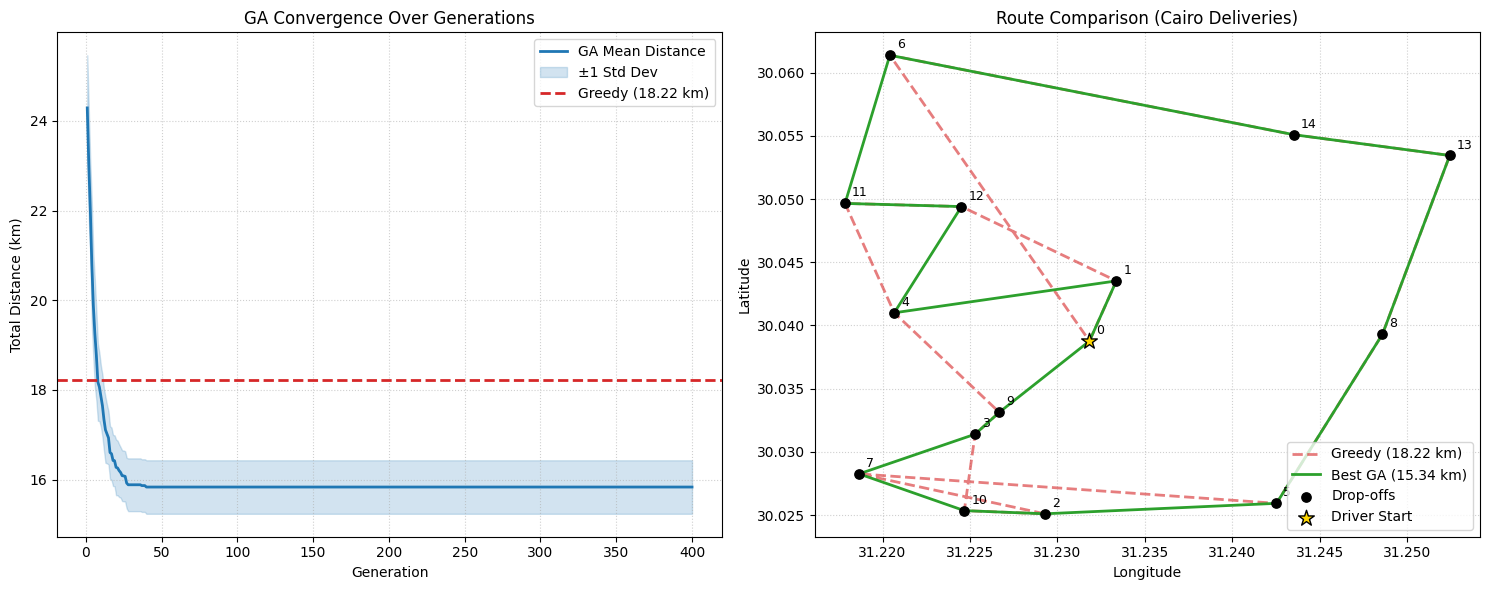

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Convergence over generations
mean_hist = np.mean(ga_histories, axis=0)
std_hist = np.std(ga_histories, axis=0)
gens = range(1, len(mean_hist) + 1)

ax1.plot(gens, mean_hist, label="GA Mean Distance", color="#1f77b4", lw=2)
ax1.fill_between(
    gens,
    mean_hist - std_hist,
    mean_hist + std_hist,
    color="#1f77b4",
    alpha=0.2,
    label="±1 Std Dev",
)
ax1.axhline(
    greedy_dist,
    color="#d62728",
    ls="--",
    lw=2,
    label=f"Greedy ({greedy_dist:.2f} km)",
)
ax1.set_title("GA Convergence Over Generations")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Total Distance (km)")
ax1.legend()
ax1.grid(True, ls=":", alpha=0.6)


# Right plot: Map of the routes
def draw_route(ax, tour, color, style, label, alpha=1.0):
  pts = nodes_df.iloc[tour + [tour[0]]]
  ax.plot(
      pts["lon"], pts["lat"], ls=style, color=color, lw=2, alpha=alpha, label=label
  )


draw_route(
    ax2, greedy_tour, "#d62728", "--", f"Greedy ({greedy_dist:.2f} km)", alpha=0.6
)
draw_route(
    ax2, best_ga_tour, "#2ca02c", "-", f"Best GA ({best_ga_dist:.2f} km)"
)

ax2.scatter(
    nodes_df["lon"][1:],
    nodes_df["lat"][1:],
    color="black",
    zorder=5,
    s=45,
    label="Drop-offs",
)
ax2.scatter(
    nodes_df["lon"][0],
    nodes_df["lat"][0],
    color="gold",
    edgecolors="black",
    zorder=6,
    s=140,
    marker="*",
    label="Driver Start",
)

for _, row in nodes_df.iterrows():
  ax2.annotate(
      f"{row['ID']}",
      (row["lon"], row["lat"]),
      textcoords="offset points",
      xytext=(5, 5),
      fontsize=9,
  )

ax2.set_title(f"Route Comparison ({SELECTED_CITY} Deliveries)")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
ax2.legend(loc="lower right")
ax2.grid(True, ls=":", alpha=0.6)

plt.tight_layout()
plt.show()